Start lemmatizer

================ МЕНЮ ================
 1 - сбор модели и сохранение в файл
 2 - вывод статистики по обучению модели
 3 - ввод собственных предложений
 4 - стресс-тест на бомбах (stress_test.txt)
 5 - базовый тест (basic_text.txt)
 0 - выход
1/4 Читаю dictionary.txt ...
Лексем: 389412
Уникальных словоформ: 3034805
Примеры:
еж -> [1, 2, 2]
ежа -> [1, 1, 2, 12]
стабильнее -> [334299]
1 -> ('еж', 'S', 'NOUN')


2/4 Читаю связи между лексемами из dict.opcorpora.xml.bz2
связей использовано: 180924
Примеры связей:
      ежист                -> ежистый
      ежистее              -> ежистый
      ежу                  -> ежить
      ежимый               -> ежить
      ежа                  -> ежить
      ежим                 -> ежимый
      ежусь                -> ежиться
      ежащийся             -> ежиться
не совпали по POS: 112


3/4 Читаю корпус annot.opcorpora.xml.bz2 ...
    Всего предложений: 110188
    Обучающих: 99169
    Тестовых:  11019


4/4 Строю словарь, частоты 

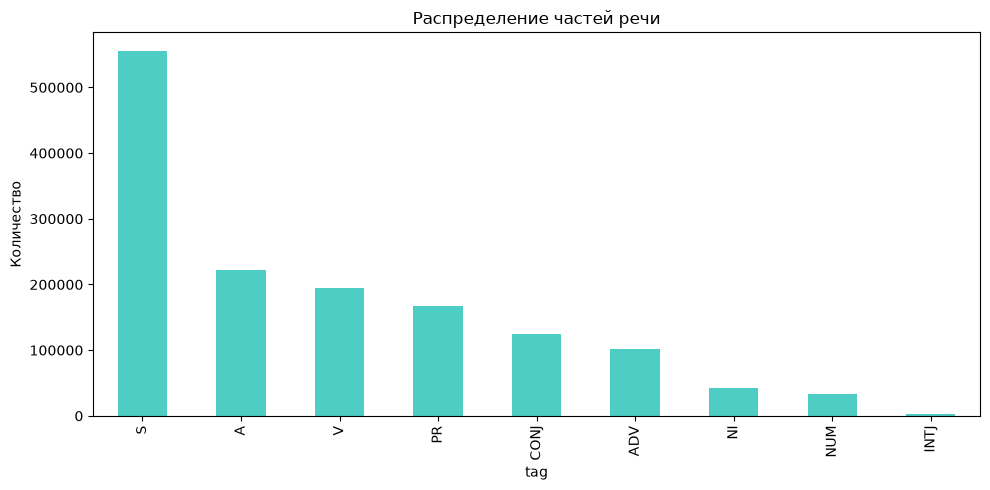


АНАЛИЗ ОМОНИМИИ В СЛОВАРЕ И КОРПУСЕ

СТАТИСТИКА ПО СЛОВАРЮ:
Всего уникальных словоформ:      3034805
Однозначных (1 разбор):          2969926 (97.86%)
Омонимов (2 разбора):              62231 (2.05%)
Омонимов (3 разбора):               2484 (0.08%)
Омонимов (4+ разборов):              164 (0.01%)


   ВСЕГО ОМОНИМОВ:    64879 (2.14%)

 СТАТИСТИКА ПО КОРПУСУ:
Всего токенов в корпусе:  1444162
Токенов-омонимов:   450000 (31.16%)
Однозначных токенов:   994162 (68.84%)

 ТОП-10 САМЫХ ЧАСТЫХ ОМОНИМОВ В КОРПУСЕ:
----------------------------------------------------------------------
   в               (54478 раз)  ->  (в, PR), (в, S)
   и               (48449 раз)  ->  (и, ADV), (и, CONJ), (и, INTJ), (и, S)
   на              (22821 раз)  ->  (на, ADV), (на, INTJ), (на, PR)
   с               (15628 раз)  ->  (с, ADV), (с, PR), (с, S)
   что             (14591 раз)  ->  (что, ADV), (что, CONJ), (что, NI)
   по              (10202 раз)  ->  (по, PR), (по, S)
   а               (8703 раз)  -> 

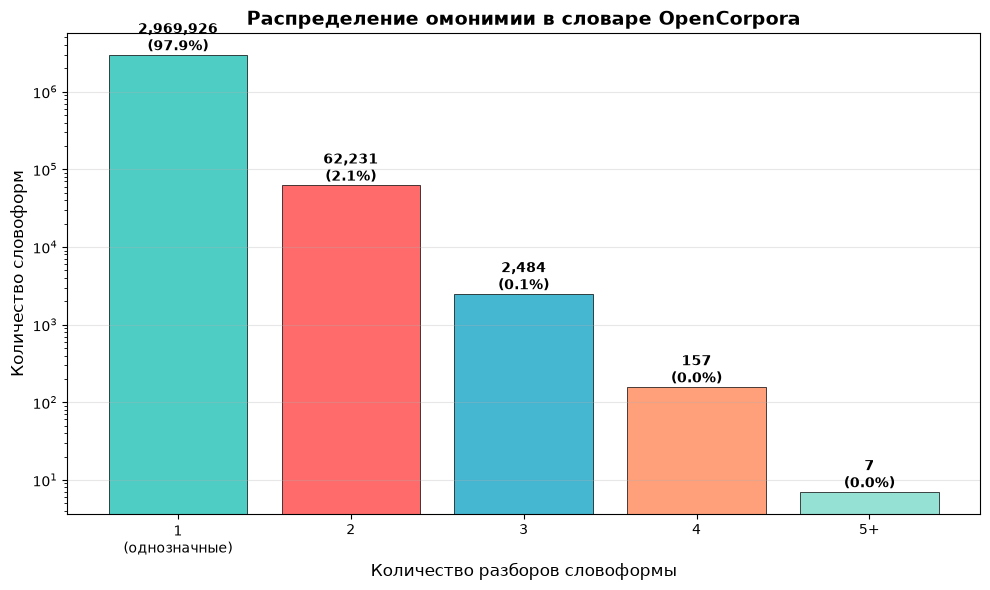


ОЦЕНКА ТОЧНОСТИ НА ТЕСТОВОЙ ВЫБОРКЕ
Тестовых предложений: 11019

СВОДНАЯ ТАБЛИЦА:
--------------------------------------------------------------------------------
Уровень                                       |    Лемма |      Тег |  Лемма+Тег
--------------------------------------------------------------------------------
Уровень 0: baseline (лемма=слово, тег=S)      |   49.19% |   38.46% |     13.95%
Уровень 1: ручные правила окончаний           |   61.55% |   54.91% |     33.23%
Уровень 2. Автоматические суффиксные правила  |   57.82% |   58.65% |     47.73%
Уровень 3А: Словарь + приоритет служебных (PR |   93.10% |   89.86% |     88.43%
Уровень 3Б: Словарь + приоритет местоимений ( |   93.76% |   91.47% |     90.04%
Уровень 4: Словарь + частоты из корпуса       |   97.30% |   95.86% |     94.85%
Уровень 5А: ЖАДНЫЙ алгоритм (экономит память) |   97.08% |   95.56% |     94.53%
Уровень 5Б: ВИТЕРБИ (глобально оптимален)     |   97.20% |   95.76% |     94.72%
Уровень 6: Витерби по лемм

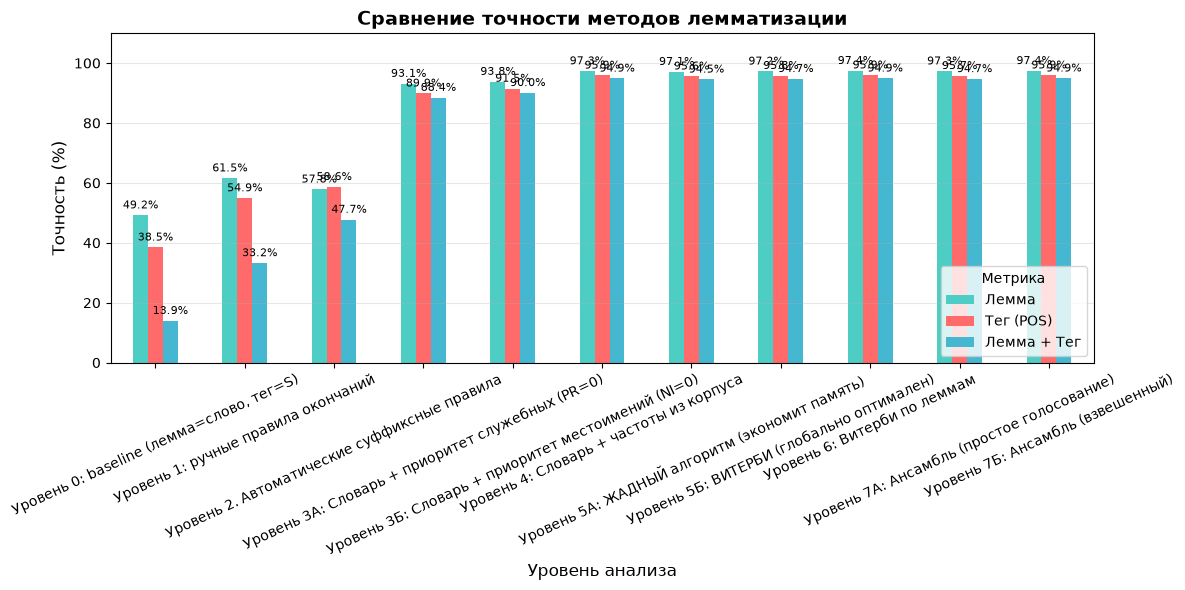


================ МЕНЮ ================
 1 - сбор модели и сохранение в файл
 2 - вывод статистики по обучению модели
 3 - ввод собственных предложений
 4 - стресс-тест на бомбах (stress_test.txt)
 5 - базовый тест (basic_text.txt)
 0 - выход
ВЫХОД


In [3]:
import pickle
import math
import pandas as pd
import os
import re
import sys
from collections import defaultdict
import bz2
import zipfile
import xml.etree.ElementTree as ET
from collections import Counter

import matplotlib.pyplot as plt

TEST_TRAIN = 10

# Словарь преобразования для типов речи

TAG_MAP = {
    'NOUN': 'S', 'VERB': 'V', 'INFN': 'V', 'ADJF': 'A', 'ADJS': 'A',
    'PRTF': 'A', 'PRTS': 'A', 'GRND': 'ADV', 'ADVB': 'ADV', 'NPRO': 'NI',
    'NUMB': 'NUM', 'NUMR': 'NUM', 'PREP': 'PR', 'CONJ': 'CONJ', 'PRCL': 'ADV',
    'INTJ': 'INTJ', 'COMP': 'A', 'PRED': 'ADV', 'UNKN': 'S', 'LATN': 'S',
}

HAND_RULES = [
    ("лись", "ться", "V"), ("лась", "ться", "V"), ("лось", "ться", "V"), ("лся", "ться", "V"),
    ("ются", "ться", "V"), ("ется", "ться", "V"), ("ится", "иться", "V"), ("ятся", "иться", "V"),
    ("тись", "ться", "V"), ("ться", "ться", "V"),
    ("уют", "овать", "V"), ("ают", "ать", "V"), ("яют", "ять", "V"), ("ют", "ть", "V"), ("ут", "ть", "V"),
    ("ет", "ть", "V"), ("ит", "ить", "V"), ("ят", "ить", "V"),
    ("ли", "ть", "V"), ("ла", "ть", "V"), ("ло", "ть", "V"), ("ть", "ть", "V"), ("л", "ть", "V"),
    ("ого", "ый", "A"), ("его", "ий", "A"), ("ому", "ый", "A"), ("ему", "ий", "A"), ("ыми", "ый", "A"),
    ("ими", "ий", "A"), ("ая", "ый", "A"), ("яя", "ий", "A"), ("ое", "ый", "A"), ("ее", "ий", "A"),
    ("ые", "ый", "A"), ("ие", "ий", "A"), ("ых", "ый", "A"), ("их", "ий", "A"), ("ую", "ый", "A"),
    ("юю", "ий", "A"), ("ой", "ый", "A"), ("ым", "ый", "A"), ("ый", "ый", "A"), ("ий", "ий", "A"),
    ("ами", "а", "S"), ("ями", "я", "S"), ("ах", "а", "S"), ("ях", "я", "S"), ("ов", "", "S"),
    ("ев", "й", "S"), ("ей", "ь", "S"), ("ам", "а", "S"), ("ям", "я", "S"), ("ом", "", "S"),
    ("ем", "ь", "S"), ("ы", "а", "S"), ("и", "я", "S"), ("у", "а", "S"), ("ю", "я", "S"), ("е", "а", "S"),
]

LEX = {}      # id лексемы - (лемма, тег, исходный POS)
PARENT = {}   # id лексемы - id "главной" лексемы (по связям)

BASE = os.getcwd()  # текущая рабочая директория

DICT_TXT = os.path.join(BASE, "dictionary.txt")

# Оптимизаторы, берем каждую 3-ю форму, то там формы в словаре повторяются
RULE_SAMPLE_EVERY = 3
MAX_SUFFIX = 5
STRIP_CHARS = ',.?!:;«»"\'()[]…—–-'

FOLLOW_LINKS = {"ADJF-ADJS", "ADJF-COMP", "ADVB-COMP", "INFN-VERB", "INFN-PRTF", "INFN-GRND", "PRTF-PRTS"}

LINKS_FILES = (
    "dict.opcorpora.xml",
    "dict.opcorpora.xml.bz2",
    "dict.opcorpora.xml.zip",
)

CORPUS_FILES = (
    "annot.opcorpora.xml.bz2",
    "annot.opcorpora.xml",
    "annot.opcorpora.xml.zip",
    "annot.opcorpora.no_ambig.xml.bz2",
    "annot.opcorpora.no_ambig.xml",
    "annot.opcorpora.no_ambig.xml.zip",
)

MODEL_FILE = os.path.join(BASE, "lab1_model.pkl")

# Сохраняет модель и выборки

def save_model(model, train_sents, test_sents):

    try:
        data = {
            "model": model,
            "train_sents": train_sents,
            "test_sents": test_sents,
        }
        with open(MODEL_FILE, "wb") as f:
            pickle.dump(data, f, protocol=pickle.HIGHEST_PROTOCOL)

    except Exception as e:
        print(f"\nОшибка сохранения: {e}")

# Интерактивный режим: пользователь вводит предложения

def interactive_parse(model, test_sents):

    print("\n" + "=" * 60)
    print("ВВОД ПРЕДЛОЖЕНИЙ")
    print("=" * 60)

    # Выбираем лучший метод
    level_fn, method_name, stats = select_best_method(model, test_sents)

    print(f"\n  Используемый метод: {method_name}")
    print("  Вводите предложения по одному.")
    print("  Для выхода введите пустую строку.")
    print("=" * 60)

    while True:
        text = input("\n> ").strip()
        if not text: break

        # Передаем model в parse_sentence!
        parsed = parse_sentence(text, level_fn, model=model)

        if not parsed:
            print("  (пустое предложение)")
            continue

        print(f"  {format_output_etalon(parsed)}")

# Разбирает предложение через указанный метод

def parse_sentence(text, level_fn, model=None):

    words = tokenize(text)
    if not words:
        return []


    parsed_raw = level_fn(words)

    if model is not None:
        result = []
        for i, (lemma, tag) in enumerate(parsed_raw):
            original_word = words[i]

            if original_word and original_word[0].isupper():
                norm_w = norm(original_word)
                if norm_w in model.forms:
                    # Проверяем, есть ли у этого слова вариант с тегом S
                    has_noun_variant = any(model.lex[lid][1] == 'S' for lid in model.forms[norm_w])

                    if has_noun_variant and tag != 'S':
                        # Ищем самую частотную лемму с тегом S
                        best_lid = None
                        max_count = -1
                        for lid in model.forms[norm_w]:
                            if model.lex[lid][1] == 'S':
                                cnt = model.emit.get((norm_w, lid), 0)
                                if cnt > max_count:
                                    max_count = cnt
                                    best_lid = lid

                        if best_lid is not None:
                            lemma, tag = model.lex[best_lid][:2]

            result.append((lemma, tag))
        return [(w, l, t) for w, (l, t) in zip(words, result)]

    return [(w, lemma, tag) for w, (lemma, tag) in zip(words, parsed_raw)]

# Формат вывода

def format_output_etalon(parsed):

    parts = []
    for word, lemma, tag in parsed:
        parts.append(f"{word}{{{lemma}={tag}}}")
    return " ".join(parts)

# Выбирает лучший метод по точности

def select_best_method(model, test_sents):

    levels = [

        ("Уровень 0: baseline (лемма=слово, тег=S)", model.level_0),
        ("Уровень 1: ручные правила окончаний", model.level_1),
        ("Уровень 2: автоматические суффиксные правила", model.level_2),
        ("Уровень 3А: Словарь + приоритет служебных (PR=0)", model.level_3_v1),
        ("Уровень 3Б: Словарь + приоритет местоимений (NI=0)", model.level_3_v2),
        ("Уровень 4: Словарь + частоты из корпуса", model.level_4),
        ("Уровень 5А: Жадный алгоритм", model.level_greedy),
        ("Уровень 5Б: Витерби по тегам", model.level_viterbi),
        ("Уровень 6: Витерби по леммам", model.level_6),
        ("Уровень 7А: Ансамбль (простое голосование)", model.level_ensemble),
        ("Уровень 7Б: Ансамбль (взвешенный)", model.level_ensemble_weighted),
    ]

    results = []

    for name, fn in levels:
        acc_l, acc_t, acc_b, *_ = evaluate(test_sents, fn)
        results.append({
            "name": name,
            "fn": fn,
            "acc_lemma": acc_l,
            "acc_tag": acc_t,
            "acc_both": acc_b,
        })
        print(f"{name}: Лемма={acc_l:.2f}%, Тег={acc_t:.2f}%, Оба={acc_b:.2f}%")

    # Вывод трех лучших методов
    top3 = sorted(results, key=lambda r: r["acc_both"], reverse=True)[:3]
    print("\n  Три лучших метода по общей точности:")
    for i, r in enumerate(top3, 1):
        print(f"    {i}. {r['name']}: Лемма={r['acc_lemma']:.2f}%, "
              f"Тег={r['acc_tag']:.2f}%, Оба={r['acc_both']:.2f}%")

    # Анализ лидеров
    max_both = max(r["acc_both"] for r in results)

    # Считаем методы одинаковыми, если разница в общей точности не больше 0.01%
    TOLERANCE = 0.01
    best_candidates = [r for r in results if r["acc_both"] >= max_both - TOLERANCE]

    if len(best_candidates) == 1:
        best = best_candidates[0]
        print(f"\n  Выбран лучший метод: {best['name']}")
        print(f"     Точность: Лемма={best['acc_lemma']:.2f}%, "
              f"Тег={best['acc_tag']:.2f}%, Оба={best['acc_both']:.2f}%")
        return best["fn"], best["name"], best

    # Несколько методов с одинаковой общей точностью
    print(f"\n  Внимание: найдено {len(best_candidates)} метода "
          f"с одинаковой общей точностью ({max_both:.2f}%):")
    for i, r in enumerate(best_candidates, 1):
        print(f"    {i}. {r['name']}: Лемма={r['acc_lemma']:.2f}%, "
              f"Тег={r['acc_tag']:.2f}%")

    max_lemma = max(r["acc_lemma"] for r in best_candidates)
    max_tag = max(r["acc_tag"] for r in best_candidates)

    best_by_lemma = [r for r in best_candidates
                     if r["acc_lemma"] >= max_lemma - TOLERANCE]
    best_by_tag = [r for r in best_candidates
                   if r["acc_tag"] >= max_tag - TOLERANCE]

    # Если один и тот же метод лучший и по леммам, и по тегам
    if (len(best_by_lemma) == 1 and len(best_by_tag) == 1
            and best_by_lemma[0] is best_by_tag[0]):
        best = best_by_lemma[0]
        print(f"\n  Выбран лучший метод (и по леммам, и по тегам): {best['name']}")
        return best["fn"], best["name"], best

    # Лидеры разные - спрашиваем пользователя
    print("\n  Лидеры по разным критериям:")
    if len(best_by_lemma) == 1 and len(best_by_tag) == 1:
        print(f"     По леммам лучше: {best_by_lemma[0]['name']} ({max_lemma:.2f}%)")
        print(f"     По тегам лучше:  {best_by_tag[0]['name']} ({max_tag:.2f}%)")

    print("\n  Выберите критерий:")
    print("    1 - Максимальная точность по леммам")
    print("    2 - Максимальная точность по тегам (частям речи)")
    print("    3 - Максимальная сумма (лемма + тег)")
    print("    4 - Показать все методы с одинаковой точностью")
    print("    0 - Использовать первый метод из списка")

    while True:
        choice = input("  Ваш выбор [0-4]: ").strip()
        if choice == "1":
            best = max(best_candidates, key=lambda r: r["acc_lemma"])
            break
        elif choice == "2":
            best = max(best_candidates, key=lambda r: r["acc_tag"])
            break
        elif choice == "3":
            best = max(best_candidates,
                       key=lambda r: r["acc_lemma"] + r["acc_tag"])
            break
        elif choice == "4":
            print("\n  Все методы-кандидаты:")
            for i, r in enumerate(best_candidates, 1):
                print(f"    {i}. {r['name']}: "
                      f"Лемма={r['acc_lemma']:.2f}%, "
                      f"Тег={r['acc_tag']:.2f}%, "
                      f"Оба={r['acc_both']:.2f}%")
            manual = input(
                "  Введите номер метода [1-{}]: ".format(len(best_candidates))
            ).strip()
            if manual.isdigit() and 1 <= int(manual) <= len(best_candidates):
                best = best_candidates[int(manual) - 1]
                break
            else:
                print("  Неверный номер, выбираю первый метод.")
                best = best_candidates[0]
                break
        elif choice == "0" or choice == "":
            best = best_candidates[0]
            break
        else:
            print("  Неверный выбор, повторите.")

    print(f"\n  Выбран метод: {best['name']}")
    print(f"     Точность: Лемма={best['acc_lemma']:.2f}%, "
          f"Тег={best['acc_tag']:.2f}%, Оба={best['acc_both']:.2f}%")
    return best["fn"], best["name"], best

def  main():
    print("Start lemmatizer")

    while True:
        print("\n" + "=" * 60)
        print("================ МЕНЮ ================")
        print(" 1 - сбор модели и сохранение в файл")
        print(" 2 - вывод статистики по обучению модели")
        print(" 3 - ввод собственных предложений")
        print(" 4 - стресс-тест на бомбах (stress_test.txt)")
        print(" 5 - базовый тест (basic_text.txt)")
        print(" 0 - выход")
        print("=" * 60)

        choice = input("Ваш выбор: ").strip()

        if choice == '0':
            print("ВЫХОД")
            break

        elif choice == '1':
            if os.path.exists(MODEL_FILE):
                os.remove(MODEL_FILE)
                print("Старый кэш удалён.")

            create_model()

        elif choice == '3':
            model, test_sents, train_sents = load_model()
            interactive_parse(model, test_sents)

        elif choice == '2':

            model, test_sents, train_sents = load_model()

            if model is None and  test_sents is None and train_sents is None:
                print("Модель не была создана, создать модель и вывести статистику")
                create_model()
            else:
                statistics_check(model, train_sents)

                print("\n")

                print_corpus_pos_stats(train_sents)

                model.analyze_ambiguity(train_sents)

                print("\n" + "="*60)
                print("ОЦЕНКА ТОЧНОСТИ НА ТЕСТОВОЙ ВЫБОРКЕ")
                print("="*60)
                print(f"Тестовых предложений: {len(test_sents)}")

                result_all = evaluate_all_levels(model, test_sents)

                print_histogram(result_all)

        elif choice == '4':
            model, test_sents, train_sents = load_model()
            if model is None:
                print("Модель не загружена.")
                continue
            model.run_file_test("stress_test.txt", test_sents)

        elif choice == '5':
            model, test_sents, train_sents = load_model()
            if model is None:
                print("Модель не загружена.")
                continue
            model.run_file_test("basic_text.txt", test_sents)

# Приводим к общему виду, строчные буквы и замена ё на е

def norm(s):
    return s.lower().replace("ё", "е")

# Разбиваем строку на слова, убирая пунктуацию

def tokenize(line):
    toks = []
    for t in line.split():
        t = t.strip(STRIP_CHARS)
        if t:
            toks.append(t)
    return toks

# открыть файл

def open_any(path):
    if path.endswith(".bz2"):
        return bz2.open(path, "rb")
    if path.endswith(".zip"):
        z = zipfile.ZipFile(path)
        return z.open(z.namelist()[0])
    return open(path, "rb")

# Идем по ссылке к инфинитиву и находим начальную форму

def apply_links():
    for lid in list(PARENT):
        root = lid
        for _ in range(10):
            if root not in PARENT:
                break
            root = PARENT[root]
        if root != lid and root in LEX:
            lemma, tag, _ = LEX[root]
            LEX[lid] = (lemma, tag, LEX[lid][2])

# Загрузка связей, фиксируем ссылки

def load_links(path):

    PARENT.clear()
    types = {}
    stats = Counter()
    bad = Counter()

    with open_any(path) as f:
        for event, el in ET.iterparse(f, events=("end",)):
            if el.tag == "type":
                types[el.get("id")] = (el.text or "").strip()

            elif el.tag == "link":
                name = types.get(el.get("type"), "?")
                stats[name] += 1

                if name in FOLLOW_LINKS:
                    a, b = name.split("-", 1)
                    fr = int(el.get("from"))
                    to = int(el.get("to"))

                    # Проверяем, что части речи совпадают с типом связи
                    pf = LEX.get(fr, (None, None, None))[2]  # исходный POS
                    pt = LEX.get(to, (None, None, None))[2]

                    if pf == a and pt == b:
                        PARENT[to] = fr
                    elif pf == b and pt == a:
                        PARENT[fr] = to
                    else:
                        bad[name] += 1

            # Очищаем элемент, чтобы не жрать память
            if el.tag in ("lemma", "link", "type"):
                el.clear()

    print(f"связей использовано: {len(PARENT)}")

    # Показываем несколько примеров связей
    print("Примеры связей:")
    count = 0

    for child_id, parent_id in list(PARENT.items())[:10]:  # первые 10
        child_lemma = LEX.get(child_id, ("?", None, None))[0]
        parent_lemma = LEX.get(parent_id, ("?", None, None))[0]
        print(f"      {child_lemma:20} -> {parent_lemma}")
        count += 1
        if count >= 8:
            break

    print(f"не совпали по POS: {sum(bad.values())}")
    if not stats:
        print("ВНИМАНИЕ: связи в XML не найдены.")

# Загрузка корпуса

def load_corpus(path):

    # Данный список имеет вид:
    # 1) Предложение первый уровень 2) Разбор где отображается изначальное слово в предложении, далее получаем его лексему
    # из списка со связями и тип лексемы

    sents = []

    with open_any(path) as f:

        # Читаем частями

        for event, el in ET.iterparse(f, events=("end",)):

            # sentence нас интересует только этот блок xml файла

            if el.tag != "sentence":
                continue

            sent = [] # Строка для предложения

            # Проходим по токенам предложения. У каждого токена разбор лежит
            # в дочернем элементе <tfr>, внутри которого - один или несколько
            # вариантов <v>; каждый вариант ссылается на лексему

            for tok in el.iter("token"):
                tfr = tok.find("tfr")
                if tfr is None:
                    continue

                # Текст слова
                text = norm((tok.get("text") or tfr.get("t") or "").strip())
                if not text:
                    continue

                # Берём омонимы
                variants = tfr.findall("v")
                if len(variants) == 0:
                    continue

                # Берем только слова у которых есть значение

                l = variants[0].find("l")
                if l is None:
                    continue

                # Пытаемся получить лемму через связи (PARENT)
                lid = l.get("id")
                resolved = None
                if lid and lid.isdigit():
                    lid = int(lid)
                    # Поднимаемся по PARENT до главной лексемы
                    # Для этого используем словарь связей dict.opcorpora.xml, загруженный ранее
                    root = lid
                    for _ in range(10):
                        if root not in PARENT:
                            break
                        root = PARENT[root]
                    if root in LEX:
                        resolved = LEX[root][:2]  # Из словаря берём (лемму, тег) ГЛАВНОЙ лексемы - это и есть результат

                if resolved:

                    # Словарь + связи

                    lemma, tag = resolved
                else:
                    # запасной вариант, ищем тег в карте тегов TAG_MAP, изначальный
                    # часть речи берем из корпуса, если не нашли ставим "S" в карте частей речи
                    lemma = norm(l.get("t") or text)
                    tag = None
                    for g in l.findall("g"):
                        v = g.get("v")
                        if v in TAG_MAP:
                            tag = TAG_MAP[v]
                            break

                    if tag is None:
                        # Проверяем, есть ли у токена id из корпуса в словаре
                        has_id = (l.get("id") or "0") not in ("", "0")
                        if has_id:

                            lemma = norm(l.get("t") or text)
                            tag = "S"
                        else:
                            # Пунктуация — пропускаем
                            continue

                if tag is None:
                    continue

                sent.append((text, lemma, tag))

            if any(lm for _, lm, _ in sent):
                sents.append(sent)

            el.clear()  # экономим память

    return sents

# Загружает модель

def load_model():

    if not os.path.exists(MODEL_FILE):
        print(f"Кэш не найден: {MODEL_FILE}")
        print("Выполните пункт 1 меню для сборки модели.")
        return None, None, None

    try:
        print(f"Загружаю модель из {MODEL_FILE} ...", end=" ", flush=True)
        with open(MODEL_FILE, "rb") as f:
            data = pickle.load(f)
        print("готово!")

        model = data["model"]
        train_sents = data["train_sents"]
        test_sents = data["test_sents"]

        print(f"Лексем: {len(model.lex)}")
        print(f"Словоформ: {len(model.forms)}")
        print(f"Тестовых предложений: {len(test_sents)}")

        return model, test_sents, train_sents
    except Exception as e:
        print(f"Ошибка загрузки: {e}")
        return None, None, None

# Создание модели

def create_model():
    if not os.path.exists(DICT_TXT):
        sys.exit(f"Не найден {DICT_TXT}")

    print("1/4 Читаю dictionary.txt ...")
    LEX, forms, blocks, lines = read_dictionary(DICT_TXT)

    print(f"Лексем: {len(LEX)}")
    print(f"Уникальных словоформ: {len(forms)}")

    print("Примеры:")
    print("еж ->", forms.get("еж"))
    print("ежа ->", forms.get("ежа"))
    print("стабильнее ->", forms.get("стабильнее"))
    print("1 ->", LEX.get(1))
    print("\n")

    links_path = find_file(LINKS_FILES)
    if links_path:
        print(f"2/4 Читаю связи между лексемами из dict.opcorpora.xml.bz2")
        load_links(links_path)
        apply_links()
    else:
        print("2/4 ВНИМАНИЕ: dict.opcorpora.xml не найден.")

    print("\n")

    corpus_path = find_file(CORPUS_FILES)

    train_sents = []
    test_sents = []

    if corpus_path:
        print(f"3/4 Читаю корпус {os.path.basename(corpus_path)} ...")
        sents = load_corpus(corpus_path)
        print(f"    Всего предложений: {len(sents)}")

        # Разделяем
        train_sents = [s for i, s in enumerate(sents) if i % TEST_TRAIN != 0]
        test_sents = [s for i, s in enumerate(sents) if i % TEST_TRAIN == 0]

        print(f"    Обучающих: {len(train_sents)}")
        print(f"    Тестовых:  {len(test_sents)}")
    else:
        print("3/4 ВНИМАНИЕ: корпус не найден.")

    print("\n")

    print("4/4 Строю словарь, частоты и правила для неизвестных слов ...")

    # Убираем тестовые формы
    test_forms = {w for s in test_sents for w, _, _ in s}

    model = Lemmatizer(LEX, forms, train_sents, test_forms, lines, blocks)

    statistics_check(model, train_sents)

    print("\n")

    print_corpus_pos_stats(train_sents)

    model.analyze_ambiguity(train_sents)

    print("\n" + "="*60)
    print("ОЦЕНКА ТОЧНОСТИ НА ТЕСТОВОЙ ВЫБОРКЕ")
    print("="*60)
    print(f"Тестовых предложений: {len(test_sents)}")

    result_all = evaluate_all_levels(model, test_sents)

    print_histogram(result_all)

    save_model(model, train_sents, test_sents)

# График и таблица по точности алгоритма разбора предложений на леммы

def print_histogram(results):

    df = pd.DataFrame(results)

    # Переименовываем столбцы для красивых подписей
    df_plot = df.rename(columns={
        "acc_lemma": "Лемма",
        "acc_tag": "Тег (POS)",
        "acc_both": "Лемма + Тег"
    })

    print("\nСВОДНАЯ ТАБЛИЦА:")
    print("-" * 80)
    print(f"{'Уровень':<45} | {'Лемма':>8} | {'Тег':>8} | {'Лемма+Тег':>10}")
    print("-" * 80)
    for _, row in df.iterrows():
        print(f"{row['name'][:45]:<45} | {row['acc_lemma']:>7.2f}% | {row['acc_tag']:>7.2f}% | {row['acc_both']:>9.2f}%")
    print("-" * 80)

    fig, ax = plt.subplots(figsize=(12, 6))

    df_plot.plot(
        x="name",
        y=["Лемма", "Тег (POS)", "Лемма + Тег"],
        kind="bar",
        ax=ax,
        color=["#4ECDC4", "#FF6B6B", "#45B7D1"]
    )

    # Подписи значений
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', fontsize=8, padding=3)

    ax.set_xlabel("Уровень анализа", fontsize=12)
    ax.set_ylabel("Точность (%)", fontsize=12)
    ax.set_title("Сравнение точности методов лемматизации",
                 fontsize=14, fontweight='bold')
    ax.set_ylim(0, 110)
    ax.legend(title="Метрика", loc='lower right')
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=25)

    plt.tight_layout()
    plt.show()

# Прогоняет все уровни через тестовую выборку, возвращает список результатов

def evaluate_all_levels(model, test_sents):

    levels = [
        ("Уровень 0: baseline (лемма=слово, тег=S)", model.level_0),
        ("Уровень 1: ручные правила окончаний", model.level_1),
        ("Уровень 2. Автоматические суффиксные правила", model.level_2),
        ("Уровень 3А: Словарь + приоритет служебных (PR=0)", model.level_3_v1),
        ("Уровень 3Б: Словарь + приоритет местоимений (NI=0)", model.level_3_v2),
        ("Уровень 4: Словарь + частоты из корпуса", model.level_4),
        ("Уровень 5А: ЖАДНЫЙ алгоритм (экономит память)", model.level_greedy),
        ("Уровень 5Б: ВИТЕРБИ (глобально оптимален)", model.level_viterbi),
        ("Уровень 6: Витерби по леммам", model.level_6),
        ("Уровень 7А: Ансамбль (простое голосование)", model.level_ensemble),
        ("Уровень 7Б: Ансамбль (взвешенный)", model.level_ensemble_weighted),
    ]

    results = []
    for name, level_fn in levels:
        acc_l, acc_t, acc_b, total, c_l, c_t, c_b = evaluate(test_sents, level_fn)
        results.append({
            "name": name,
            "total": total,
            "acc_lemma": acc_l,
            "acc_tag": acc_t,
            "acc_both": acc_b,
        })
    return results


# Открываем файл со связями

def find_file(names):
    for n in names:
        p = os.path.join(BASE, n)
        if os.path.exists(p):
            return p
    return None

# Чтение словаря

def read_dictionary(path):
    global LEX
    LEX.clear()

    blocks = [] # Новое обновление хранит id леммы и строку
    # понадобится для суффиксального анализа и собирания статистики по суффиксам

    forms = defaultdict(list)
    with open(path, encoding="utf-8") as f:
        lines = f.read().splitlines()

    i = 0
    n = len(lines)

    while i < n:

        # Создаем список лексем

        line = lines[i].strip()

        # Если не номер лексемы
        if not line.isdigit():
            i += 1
            continue

        lid = int(line) # Номер лексемы
        lemma_line_idx = i + 1 # Строка леммы
        i += 1
        if i >= n:
            break


        lem_line = lines[i].strip()

        if '\t' not in lem_line:
            i += 1
            continue

        lemma_form, tags = lem_line.split('\t', 1)

        # Старая часть речи ее обозначение

        pos = re.split(r'[,\s]+', tags.strip())[0].upper()

        # Преобразование тегов

        tag = TAG_MAP.get(pos, 'S')

        lemma = norm(lemma_form)

        LEX[lid] = (lemma, tag, pos)

        forms[lemma].append(lid)

        blocks.append((lid, lemma_line_idx))

        # Создание словоформ

        i += 1
        while i < n and lines[i].strip() and not lines[i].strip().isdigit():
            form_line = lines[i].strip()
            if '\t' in form_line:
                form = norm(form_line.split('\t', 1)[0])
                forms[form].append(lid)
            i += 1

    return LEX, forms, blocks, lines

class Lemmatizer:
    def __init__(self, lex_dict, forms_dict, train_sents,  test_forms, lines, blocks):
        self.lex = lex_dict
        self.forms = forms_dict
        self.lines = lines

        self.blocks = blocks
        self.test_forms = test_forms

        # Статистика:

        self.form_count = Counter() # Словоформы
        self.emit = Counter() # Словоформы в лексему
        self.trans = Counter() # Последовательность тегов
        self.prev_total = Counter()
        self.lex_trans = Counter()
        self.lex_total = Counter()
        self.n_tags = len(set(tag for sent in train_sents for _, _, tag in sent if tag))

        self.rules = {}
        self.rules_total = {}

        print("Собираю статистику...")
        self._build_corpus_stats(train_sents)

        print("Строю суффиксные правила...")
        self._build_suffix_rules()

        print("Модель готова!")

    def _build_corpus_stats(self, train_sents):

        for sent in train_sents:
            prev_tag = "<s>"
            prev_lemma = None

            for word, lemma, tag in sent:
                # Частота словоформы
                self.form_count[word] += 1

                # Частота лексемы берем словоформу и ищем лексему
                if word in self.forms:
                    for lid in self.forms[word]:
                        if self.lex[lid][0] == lemma and self.lex[lid][1] == tag:
                            self.emit[(word, lid)] += 1
                            break

                # сколько раз один тег идет за другим
                self.trans[(prev_tag, tag)] += 1
                self.prev_total[prev_tag] += 1

                # сколько раз перед тегом идет лемма
                if prev_lemma is not None:
                    self.lex_trans[(prev_lemma, tag)] += 1
                    self.lex_total[prev_lemma] += 1

                prev_tag = tag
                prev_lemma = lemma


    # Теперь построим суффиксное правило будем измерять длину
    # суффикса от 1 до 5, смотрим в словарь, ищем формы лексемы
    # и определяем общую часть путем обрезания до общей части, была
    # проблема слово приптовалюту преобразовывало в криптовалют!

    def _build_suffix_rules(self):

        raw = Counter()
        n = len(self.lines)
        k = 0  # счётчик обработанных форм (для сэмплирования)

        print(f"   Обрабатываю {len(self.blocks)} лексем...")

        for lid, start in self.blocks:
            # Получаем лемму и тег из LEX
            if lid not in self.lex:
                continue
            lemma, tag, pos = self.lex[lid]

            j = start
            while j < n and self.lines[j].strip() and not self.lines[j].strip().isdigit():
                if '\t' in self.lines[j]:
                    form = norm(self.lines[j].split('\t', 1)[0].strip())
                    k += 1

                    if (k % RULE_SAMPLE_EVERY == 0
                            and len(form) >= 3
                            and form not in self.test_forms):

                        # Находим общую часть формы и леммы
                        p = 0
                        m = min(len(form), len(lemma))
                        while p < m and form[p] == lemma[p]:
                            p += 1

                        cut = form[p:]
                        add = lemma[p:]

                        for L in range(1, min(MAX_SUFFIX, len(form) - 1) + 1):
                            suf = form[-L:]
                            raw[(suf, cut, add, tag)] += 1
                j += 1

        print(f"   Обработано форм: {k}, собрано правил: {len(raw)}")

        # Группируем по суффиксам
        grouped = defaultdict(list)
        for (suf, cut, add, tag), count in raw.items():
            grouped[suf].append((count, cut, add, tag))

        # Берём топ-5 для каждого суффикса
        for suf, items in grouped.items():
            items.sort(reverse=True)
            self.rules[suf] = items[:5]
            self.rules_total[suf] = sum(c for c, _, _, _ in items)

        print(f"Готово! Уникальных суффиксов: {len(self.rules)}")

    # Если слово с заглавной буквы отдаем приоритет S для методов Витерби

    def best_S(self, w_norm, is_capital, lemma, tag):

        if not is_capital or tag == "S" or w_norm not in self.forms:
            return (lemma, tag)

        best_lid = None
        best_count = -1

        for lid in self.forms[w_norm]:
            if self.lex[lid][1] != "S":
                continue
            cnt = self.emit.get((w_norm, lid), 0)
            if cnt > best_count:
                best_count = cnt
                best_lid = lid

        if best_lid is None:
            return (lemma, tag)

        s_lemma, s_tag = self.lex[best_lid][:2]
        return (s_lemma, s_tag)


    # Загружает файл с предложениями

    def run_file_test(self, filename, test_sents):

        if not os.path.exists(filename):
            print(f"\n  Файл {filename} не найден.")
            return

        with open(filename, "r", encoding="utf-8") as f:
            lines = [line.strip() for line in f if line.strip()]

        if not lines:
            print(f"\n  Файл {filename} пуст.")
            return

        print(f"\n" + "=" * 70)
        print(f"ТЕСТ ФАЙЛА: {filename}")
        print(f"Предложений: {len(lines)}")
        print("=" * 70)

        # Выбираем лучший метод
        level_fn, method_name, stats = select_best_method(self, test_sents)

        print(f"\nИспользуемый метод: {method_name}")
        print(f"Точность: Лемма={stats['acc_lemma']:.2f}%, "
              f"Тег={stats['acc_tag']:.2f}%, Оба={stats['acc_both']:.2f}%")
        print("-" * 70)

        # Прогоняем каждое предложение
        for i, line in enumerate(lines, 1):
            if not line:
                continue

            parsed = parse_sentence(line, level_fn, model=self)
            if not parsed:
                continue

            parts = [f"{w}{{{l}={t}}}" for w, l, t in parsed]

            print(f"\n[{i:2d}] {line}")
            print(f"     {' '.join(parts)}")

    def level_0(self, words):
        # Слово сущ + словоформа равна лемме
        return [(w, "S") for w in words]

    def level_1(self, words):
        # Применяем статический словарь он помогает определить как менять окончания и предположительную часть речи
        # если словарь неполный то применяем уровень выше
        result = []
        for w in words:
            for suf, rep, tag in HAND_RULES:
                if len(w) > len(suf) + 1 and w.endswith(suf):
                    result.append((w[:-len(suf)] + rep, tag))
                    break
            else:
                result.append((w, "S"))
        return result

    # Автоматический подбор суффикса

    def level_2(self, words):

        result = []
        for w in words:
            # Пытаемся угадать по суффиксам
            guessed = self._guess(w)
            # Берём самый вероятный вариант
            best = max(guessed, key=lambda x: x[2])
            result.append((best[0], best[1]))
        return result

    # Суть у нас есть статистика по суффиксам rules имеет вид для суффикса в словоформе есть пара для начального слова их может быть несколько, а также сохраняется тег, обрезаем как только нашли совпадения смотрим что получилось и подставляем самый частый суффикс

    # На примере удобней:
    # Правило для суффикса 'ет':
    # ет -> ю (тег V): 2720 раз - выбираем этот для ет, у слова суффикс ет, значит начальная форма на ю, замена
    # ет -> л (тег V): 685 раз
    # ует -> овал (тег V): 555 раз

    def _guess(self, w):

        # Пробуем суффиксы от длинных к коротким (5, 4, 3, 2, 1)
        for L in range(min(MAX_SUFFIX, len(w)), 0, -1):
            suf = w[-L:]  # последние L символов слова

            rs = self.rules.get(suf)
            if not rs:
                continue

            total = self.rules_total[suf]

            if L > 1 and total < MAX_SUFFIX:
                continue

            candidates = {}
            for count, cut, add, tag in rs:

                if cut and not w.endswith(cut):
                    continue

                lemma = w[:len(w) - len(cut)] + add
                candidates[(lemma, tag)] = candidates.get((lemma, tag), 0) + count

            if candidates:
                items = sorted(candidates.items(), key=lambda x: -x[1])[:3]
                return [(l, t, c / total) for (l, t), c in items]

        return [(w, 'S', 1.0)]

    # Словарь + приоритет тега

    def level_3_v1(self, words):

        # Чем меньше число, тем "важнее" тег (служебные части речи приоритетнее)
        TAG_PRIORITY = {
            'NI': 0, 'CONJ': 1, 'NUM': 2, 'PR': 3,
            'A': 4, 'V': 5, 'ADV': 6, 'INTJ': 6, 'S': 7
        }

        result = []
        for w in words:
            if w in self.forms:
                lids = self.forms[w]
                # Если вариантов несколько, берем тот, у которого тег имеет меньший приоритет
                best_lid = min(lids, key=lambda lid: TAG_PRIORITY.get(self.lex[lid][1], 9))
                lemma, tag = self.lex[best_lid][:2]
                result.append((lemma, tag))
            else:
                # Слова нет в словаре: используем уровень 2
                guessed = self._guess(w)
                best = max(guessed, key=lambda x: x[2])
                result.append((best[0], best[1]))

        return result

    def level_3_v2(self, words):

        # Чем меньше число, тем "важнее" тег (служебные части речи приоритетнее)
        TAG_PRIORITY = {
            'PR': 0, 'CONJ': 1, 'NI': 1.5, 'ADV': 3,
            'V': 4, 'A': 5, 'NUM': 6, 'INTJ': 6, 'S': 7
        }

        result = []
        for w in words:
            if w in self.forms:
                lids = self.forms[w]
                # Если вариантов несколько, берем тот, у которого тег имеет меньший приоритет
                best_lid = min(lids, key=lambda lid: TAG_PRIORITY.get(self.lex[lid][1], 9))
                lemma, tag = self.lex[best_lid][:2]
                result.append((lemma, tag))
            else:
                # Слова нет в словаре: используем уровень 2
                guessed = self._guess(w)
                best = max(guessed, key=lambda x: x[2])
                result.append((best[0], best[1]))

        return result
    # Словарь + частоты разборов из корпуса (emit)

    def level_4(self, words):

        result = []
        for w in words:
            if w in self.forms:
                lids = self.forms[w]

                # Выбираем id лексемы с максимальной частотой в emit
                best_lid = max(lids, key=lambda lid: self.emit.get((w, lid), 0))

                lemma, tag = self.lex[best_lid][:2]
                result.append((lemma, tag))
            else:

                guessed = self._guess(w)
                best = max(guessed, key=lambda x: x[2])
                result.append((best[0], best[1]))

        return result

    # Жадный алгоритм: на каждом шаге выбирает лучший вариант,
    # не думая о будущем. Экономит память (O(K)), мы проверим так ли сильно он проигрывает в точность алгоритму ВИТЕРБИ
    def level_greedy(self, words):

        if not words:
            return []

        ALPHA = 0.1
        result = []
        prev_tag = "<s>"  # начало предложения

        # Запоминаем регистр до нормализации
        is_capitalized = [bool(w) and w[0].isupper() for w in words]

        # Нормализуем для поиска в словаре
        words_norm = [norm(w) for w in words]

        for i, w in enumerate(words_norm):
            # Получаем кандидатов
            if w in self.forms:
                lids = self.forms[w]
                candidates = []
                for lid in lids:
                    lemma, tag = self.lex[lid][:2]
                    count = self.emit.get((w, lid), 0)
                    total = sum(self.emit.get((w, other_lid), 0) for other_lid in lids)
                    emit_prob = (count + ALPHA) / (total + ALPHA * len(lids))
                    candidates.append((lemma, tag, emit_prob))
            else:
                guessed = self._guess(w)
                candidates = [(l, t, p) for l, t, p in guessed]

            # жадный выбор: сразу выбираем лучший вариант
            best_score = -float('inf')
            best_cand = candidates[0]

            for lemma, tag, emit_prob in candidates:

                score = math.log(emit_prob)

                if i > 0:
                    trans_count = self.trans.get((prev_tag, tag), 0)
                    prev_count = self.prev_total.get(prev_tag, 0)
                    trans_prob = (trans_count + ALPHA) / (prev_count + ALPHA * self.n_tags)
                    score += math.log(trans_prob)

                if score > best_score:
                    best_score = score
                    best_cand = (lemma, tag)


            # Отдаем приоритет
            best_cand = self.best_S(w, is_capitalized[i], *best_cand)

            result.append(best_cand)
            prev_tag = best_cand[1]

        return result

    # Алгоритм Витерби: сохраняет все варианты, выбирает лучший путь в конце.
    # Требует больше памяти (O(N*K))

    def level_viterbi(self, words):

        if not words:
            return []

        ALPHA = 0.1

        # Запоминаем регистр до нормализации
        is_capitalized = [bool(w) and w[0].isupper() for w in words]

        # Нормализуем для поиска в словаре
        words_norm = [norm(w) for w in words]

        # Получаем кандидатов для каждого слова
        cands = []
        for w in words_norm:
            if w in self.forms:
                lids = self.forms[w]
                candidates = []
                for lid in lids:
                    lemma, tag = self.lex[lid][:2]
                    count = self.emit.get((w, lid), 0)
                    total = sum(self.emit.get((w, other_lid), 0) for other_lid in lids)
                    emit_prob = (count + ALPHA) / (total + ALPHA * len(lids))
                    candidates.append((lemma, tag, math.log(emit_prob)))
                cands.append(candidates)
            else:
                guessed = self._guess(w)
                cands.append([(l, t, math.log(p + ALPHA)) for l, t, p in guessed])

        best = []

        # Сохраняем вероятности

        for i, cs in enumerate(cands):
            row = []
            for j, (lemma, tag, emit_score) in enumerate(cs):
                if i == 0:
                    # Первое слово: только эмиссия
                    row.append((emit_score, -1))
                else:
                    best_score = -float('inf')
                    best_prev = 0

                    for k, (prev_lemma, prev_tag, _) in enumerate(cands[i-1]):
                        trans_count = self.trans.get((prev_tag, tag), 0)
                        prev_count = self.prev_total.get(prev_tag, 0)
                        trans_prob = (trans_count + ALPHA) / (prev_count + ALPHA * self.n_tags)
                        trans_score = math.log(trans_prob)

                        score = best[i-1][k][0] + trans_score + emit_score

                        if score > best_score:
                            best_score = score
                            best_prev = k

                    row.append((best_score, best_prev))

            best.append(row)

        # Восстанавливаем лучший путь
        j = max(range(len(best[-1])), key=lambda k: best[-1][k][0])

        result = []
        for i in range(len(words_norm) - 1, -1, -1):

            lemma, tag, _ = cands[i][j]

            # Приоритет существительного
            lemma, tag = self.best_S(words_norm[i], is_capitalized[i], lemma, tag)

            result.append((lemma, tag))
            j = best[i][j][1]

        return result[::-1]  # разворачиваем

    # Витерби с контекстом по леммам  = Витерби + леммы (для уточнения)
    def level_6(self, words):

        if not words:
            return []

        # Параметры сглаживания
        ALPHA = 0.1
        LEX_ALPHA = 12.0
        MIN_LEX_COUNT = 10

        # Запоминаем регистр до нормализации
        is_capitalized = [bool(w) and w[0].isupper() for w in words]

        # Нормализуем для поиска в словаре
        words_norm = [norm(w) for w in words]

        # Получаем кандидатов для каждого слова
        cands = []
        for w in words_norm:
            if w in self.forms:
                lids = self.forms[w]
                candidates = []
                for lid in lids:
                    lemma, tag = self.lex[lid][:2]
                    count = self.emit.get((w, lid), 0)
                    total = sum(self.emit.get((w, other_lid), 0) for other_lid in lids)
                    emit_prob = (count + ALPHA) / (total + ALPHA * len(lids))
                    candidates.append((lemma, tag, math.log(emit_prob)))
                cands.append(candidates)
            else:

                guessed = self._guess(w)
                cands.append([(l, t, math.log(p + ALPHA)) for l, t, p in guessed])

        # Витерби с учётом лемм
        best = []

        for i, cs in enumerate(cands):
            row = []
            for j, (lemma, tag, emit_score) in enumerate(cs):
                if i == 0:
                    row.append((emit_score, -1))
                else:
                    best_score = -float('inf')
                    best_prev = 0

                    # Для каждого предыдущего кандидата
                    for k, (prev_lemma, prev_tag, _) in enumerate(cands[i-1]):

                        trans_count = self.trans.get((prev_tag, tag), 0)
                        prev_count = self.prev_total.get(prev_tag, 0)
                        base_prob = (trans_count + ALPHA) / (prev_count + ALPHA * self.n_tags)

                        lex_count = self.lex_total.get(prev_lemma, 0)

                        if lex_count >= MIN_LEX_COUNT:

                            lex_trans_count = self.lex_trans.get((prev_lemma, tag), 0)

                            refined_prob = (lex_trans_count + LEX_ALPHA * base_prob) / (lex_count + LEX_ALPHA)
                        else:

                            refined_prob = base_prob

                        trans_score = math.log(max(refined_prob, 1e-12))

                        # Общий score
                        score = best[i-1][k][0] + trans_score + emit_score

                        if score > best_score:
                            best_score = score
                            best_prev = k

                    row.append((best_score, best_prev))

            best.append(row)

        j = max(range(len(best[-1])), key=lambda k: best[-1][k][0])

        result = []
        for i in range(len(words_norm) - 1, -1, -1):

            lemma, tag, _ = cands[i][j]
            lemma, tag = self.best_S(words_norm[i], is_capitalized[i], lemma, tag)

            result.append((lemma, tag))
            j = best[i][j][1]

        return result[::-1]  # разворачиваем

    # Ансамблирование: голосование всех уровней
    # Каждый уровень "голосует" за свой вариант, выбираем большинством

    def level_ensemble(self, words):

        # Запускаем все уровни
        predictions = [
            self.level_0(words),
            self.level_1(words),
            self.level_2(words),
            self.level_3_v1(words),
            self.level_3_v2(words),
            self.level_4(words),
            self.level_greedy(words),
            self.level_viterbi(words),
            self.level_6(words),
        ]

        result = []
        # Для каждой позиции считаем голоса
        for i in range(len(words)):
            votes = Counter()
            for level_pred in predictions:
                lemma, tag = level_pred[i]
                votes[(lemma, tag)] += 1

            # Выбираем вариант с большинством голосов
            best = votes.most_common(1)[0][0]
            result.append(best)

        return result

    # Взвешенное голосование: более точные уровни имеют больший вес
    # Веса можно подобрать на валидационной выборке

    def level_ensemble_weighted(self, words):

        # Веса на основе ожидаемой точности (чем точнее уровень, тем больше вес)
        weights = {
            'level_0': 1.0,        # baseline - самый низкий вес
            'level_1': 2.0,        # ручные правила
            'level_2': 2.5,        # суффиксные правила
            'level_3_v1': 4.5,     # словарь + приоритет служебных
            'level_3_v2': 5.0,     # словарь + приоритет местоимений (лучше)
            'level_4': 5.5,        # словарь + частоты
            'level_greedy': 6.0,   # жадный алгоритм
            'level_viterbi': 6.5,  # Витерби по тегам
            'level_6': 7.0,        # Витерби по леммам - самый высокий вес
        }

        # Запускаем все уровни
        predictions = {
            'level_0': self.level_0(words),
            'level_1': self.level_1(words),
            'level_2': self.level_2(words),
            'level_3_v1': self.level_3_v1(words),
            'level_3_v2': self.level_3_v2(words),
            'level_4': self.level_4(words),
            'level_greedy': self.level_greedy(words),
            'level_viterbi': self.level_viterbi(words),
            'level_6': self.level_6(words),
        }

        result = []
        for i in range(len(words)):
            votes = Counter()
            for level_id, level_pred in predictions.items():
                lemma, tag = level_pred[i]
                votes[(lemma, tag)] += weights[level_id]

            best = votes.most_common(1)[0][0]
            result.append(best)

        return result

    # Анализ омонимии: сколько словоформ имеют несколько разборов

    def analyze_ambiguity(self, train_sents):

            print("\n" + "="*70)
            print("АНАЛИЗ ОМОНИМИИ В СЛОВАРЕ И КОРПУСЕ")
            print("="*70)

            total_forms = len(self.forms)
            one_variant = 0
            two_variants = 0
            three_variants = 0
            four_plus_variants = 0

            ambiguity_counts = Counter()

            for word, lids in self.forms.items():
                # Уникальные (лемма, тег) для этой формы
                unique_parses = set()
                for lid in lids:
                    lemma, tag = self.lex[lid][:2]
                    unique_parses.add((lemma, tag))

                n = len(unique_parses)
                ambiguity_counts[n] += 1

                if n == 1:
                    one_variant += 1
                elif n == 2:
                    two_variants += 1
                elif n == 3:
                    three_variants += 1
                else:
                    four_plus_variants += 1

            print(f"\nСТАТИСТИКА ПО СЛОВАРЮ:")
            print(f"Всего уникальных словоформ:     {total_forms:>8}")
            print(f"Однозначных (1 разбор):         {one_variant:>8} ({one_variant/total_forms*100:.2f}%)")
            print(f"Омонимов (2 разбора):           {two_variants:>8} ({two_variants/total_forms*100:.2f}%)")
            print(f"Омонимов (3 разбора):           {three_variants:>8} ({three_variants/total_forms*100:.2f}%)")
            print(f"Омонимов (4+ разборов):         {four_plus_variants:>8} ({four_plus_variants/total_forms*100:.2f}%)")

            total_ambiguous = two_variants + three_variants + four_plus_variants
            print("\n")
            print(f"   ВСЕГО ОМОНИМОВ: {total_ambiguous:>8} ({total_ambiguous/total_forms*100:.2f}%)")

            # Статистика по корпусу
            print(f"\n СТАТИСТИКА ПО КОРПУСУ:")

            total_tokens = 0
            ambiguous_tokens = 0
            ambiguous_in_corpus = Counter()

            for sent in train_sents:
                for word, lemma, tag in sent:
                    total_tokens += 1
                    if word in self.forms:
                        unique_parses = set()
                        for lid in self.forms[word]:
                            l, t = self.lex[lid][:2]
                            unique_parses.add((l, t))
                        if len(unique_parses) > 1:
                            ambiguous_tokens += 1
                            ambiguous_in_corpus[word] += 1

            print(f"Всего токенов в корпусе: {total_tokens:>8}")
            print(f"Токенов-омонимов: {ambiguous_tokens:>8} ({ambiguous_tokens/total_tokens*100:.2f}%)")
            print(f"Однозначных токенов: {total_tokens - ambiguous_tokens:>8} ({(total_tokens - ambiguous_tokens)/total_tokens*100:.2f}%)")

            # Топ-10 самых частых омонимов
            print(f"\n ТОП-10 САМЫХ ЧАСТЫХ ОМОНИМОВ В КОРПУСЕ:")
            print("-" * 70)
            for word, count in ambiguous_in_corpus.most_common(10):
                unique_parses = set()
                for lid in self.forms[word]:
                    l, t = self.lex[lid][:2]
                    unique_parses.add((l, t))
                parses_str = ", ".join([f"({l}, {t})" for l, t in sorted(unique_parses)])
                print(f"   {word:<15} ({count:>4} раз)  ->  {parses_str}")

            # Топ-10 самых "запутанных" омонимов (по числу разборов)
            print(f"\n ТОП-10 САМЫХ МНОГОЗНАЧНЫХ СЛОВ:")
            print("-" * 70)
            max_ambiguity = []
            for word, lids in self.forms.items():
                unique_parses = set()
                for lid in lids:
                    l, t = self.lex[lid][:2]
                    unique_parses.add((l, t))
                if len(unique_parses) >= 3:
                    max_ambiguity.append((word, len(unique_parses), unique_parses))

            max_ambiguity.sort(key=lambda x: -x[1])
            for word, n, parses in max_ambiguity[:10]:
                parses_str = ", ".join([f"({l}, {t})" for l, t in sorted(parses)])
                print(f"   {word:<15} ({n} разборов):  {parses_str}")

            # Анализ пар тегов в омонимах
            print(f"\n ТИПИЧНЫЕ ПАРЫ ОМОНИМИЧНЫХ ТЕГОВ:")
            print("-" * 70)
            tag_pairs = Counter()
            for word, lids in self.forms.items():
                tags = set()
                for lid in lids:
                    tags.add(self.lex[lid][1])
                if len(tags) > 1:
                    tags_list = sorted(tags)
                    for i in range(len(tags_list)):
                        for j in range(i + 1, len(tags_list)):
                            tag_pairs[(tags_list[i], tags_list[j])] += 1

            for (t1, t2), count in tag_pairs.most_common(10):
                print(f"   {t1:<5} <-> {t2:<5} : {count:>5} словоформ")

            # ГРАФИК
            self._plot_ambiguity(ambiguity_counts, total_forms)

            return {
                "total_forms": total_forms,
                "one_variant": one_variant,
                "ambiguous": total_ambiguous,
                "ambiguous_pct": total_ambiguous / total_forms * 100,
            }


    # Строит график распределения омонимии

    def _plot_ambiguity(self, ambiguity_counts, total_forms):

        categories = ['1\n(однозначные)', '2', '3', '4', '5+']
        values = [
            ambiguity_counts.get(1, 0),
            ambiguity_counts.get(2, 0),
            ambiguity_counts.get(3, 0),
            ambiguity_counts.get(4, 0),
            sum(v for k, v in ambiguity_counts.items() if k >= 5),
        ]
        percentages = [v / total_forms * 100 for v in values]

        fig, ax = plt.subplots(figsize=(10, 6))

        colors = ['#4ECDC4', '#FF6B6B', '#45B7D1', '#FFA07A', '#95E1D3']
        bars = ax.bar(categories, values, color=colors, edgecolor='black', linewidth=0.5)

        # Подписи значений
        for bar, val, pct in zip(bars, values, percentages):
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2., height,
                f'{val:,}\n({pct:.1f}%)',
                ha='center', va='bottom', fontsize=10, fontweight='bold'
            )

        ax.set_xlabel("Количество разборов словоформы", fontsize=12)
        ax.set_ylabel("Количество словоформ", fontsize=12)
        ax.set_title("Распределение омонимии в словаре OpenCorpora",
                         fontsize=14, fontweight='bold')
        ax.grid(axis='y', alpha=0.3)
        ax.set_yscale('log')

        plt.tight_layout()
        plt.show()


# Диагностика существования слова

def diagnose_word(model, word, train_sents):

    print(f" ДИАГНОСТИКА СЛОВА: '{word}'")

    # Есть ли слово в словаре
    if word in model.forms:
        print(f" Слово '{word}' есть в словаре (forms)")
        print(f"  id лексем: {model.forms[word]}")
        for lid in model.forms[word]:
            if lid in model.lex:
                lemma, tag, pos = model.lex[lid]
                print(f"  Лексема {lid}: лемма='{lemma}', тег='{tag}', POS='{pos}'")
    else:
        print(f" Слова '{word}' НЕТ в словаре (forms)")

    # Сколько раз слово встречается в обучающем корпусе
    word_in_corpus = [(w, l, t) for s in train_sents for w, l, t in s if w == word]
    print(f"\nВ обучающем корпусе '{word}' встречается {len(word_in_corpus)} раз:")
    for w, l, t in word_in_corpus[:5]:
        print(f"  форма='{w}', лемма='{l}', тег='{t}'")

    # Есть ли слово в счетчики разборов
    emit_entries = [(lid, count) for (form, lid), count in model.emit.items() if form == word]
    if emit_entries:
        print(f"\n Слово '{word}' есть в emit (счётчик разборов):")
        for lid, count in emit_entries:
            lemma, tag, _ = model.lex[lid]
            print(f"  ({lemma}, {tag}): {count} раз")
    else:
        print(f"\n Слова '{word}' НЕТ в emit")

    # Проверяем совпадение лемм и тегов
    if word in model.forms and word_in_corpus:
        print(f"\nПроверяем совпадение лемм и тегов:")
        for w, corpus_lemma, corpus_tag in word_in_corpus[:3]:
            found = False
            for lid in model.forms[word]:
                dict_lemma, dict_tag, _ = model.lex[lid]
                if dict_lemma == corpus_lemma and dict_tag == corpus_tag:
                    print(
                        f"Найдено совпадение: корпус ({corpus_lemma}, {corpus_tag}) == словарь ({dict_lemma}, {dict_tag})")
                    found = True
                    break
            if not found:
                print(f"НЕТ совпадения: корпус ({corpus_lemma}, {corpus_tag}) не найден в словаре")
                print(f"Доступные разборы в словаре:")
                for lid in model.forms[word]:
                    dl, dt, _ = model.lex[lid]
                    print(f"({dl}, {dt})")

def statistics_check(model, train_sents):

    print("\n=== РЕЗУЛЬТАТЫ СБОРА СТАТИСТИКИ ===")

    # Частоты словоформ
    print(f"\n1) Всего уникальных словоформ: {len(model.form_count)}")
    print(f"   Топ-5 самых частых:")
    for word, count in model.form_count.most_common(5):
        print(f"      {word}: {count} раз")

    # Частоты разборов
    print(f"\n2) Всего уникальных пар (форма, разбор): {len(model.emit)}")
    print(f"   Пример: слово 'мама'")

    word = "мама"

    diagnose_word(model, word, train_sents)

    for (form, lid), count in model.emit.items():
        if form == word:
            lemma, tag = model.lex[lid][:2]
            print(f"мама -> {lemma}={tag}: {count} раз")

    # Биграммы тегов тег/тег
    print(f"\n3) Всего уникальных биграмм тегов: {len(model.trans)}")
    print(f"Топ-5 переходов:")
    for (pt, ct), count in model.trans.most_common(5):
        print(f"      {pt} -> {ct}: {count} раз")

    # лексема/тег
    print(f"\n4) Всего уникальных пар (лемма, тег): {len(model.lex_trans)}")
    print(f"Пример: после леммы 'этот'")
    for (pl, ct), count in model.lex_trans.items():
        if pl == "этот":
            print(f"      этот -> {ct}: {count} раз")

    # суффикс: нач суф, вставленный, тег, число
    print(f"\n5) Всего суффиксных правил: {len(model.rules)}")
    print(f"   Правило для суффикса 'ет':")
    if "ет" in model.rules:
        for count, cut, add, tag in model.rules["ет"][:3]:
            print(f"{cut} -> {add} (тег {tag}): {count} раз")

# Выводит статистику распределения частей речи

def print_corpus_pos_stats(train_sents):

    tags = [tag for sent in train_sents for _, _, tag in sent if tag is not None]
    df = pd.DataFrame({"tag": tags})
    stats = df["tag"].value_counts()

    print("\nСтатистика частей речи:")
    for tag, count in stats.items():
        print(f"  {tag}: {count} ({count/len(df)*100:.2f}%)")

    # График в одну строку
    stats.plot(kind="bar", figsize=(10, 5), color="#4ECDC4")
    plt.title("Распределение частей речи")
    plt.ylabel("Количество")
    plt.tight_layout()
    plt.show()

# Оценивает точность уровня на тестовой выборке

def evaluate(test_sents, level_fn):

    total_tokens = 0
    correct_lemma = 0
    correct_tag = 0
    correct_both = 0

    for sent in test_sents:
        # Извлекаем только слова
        words = [word for word, gold_lemma, gold_tag in sent]

        # Прогоняем через уровень модели
        predicted = level_fn(words)

        # Сравниваем с эталоном
        for (word, gold_lemma, gold_tag), (pred_lemma, pred_tag) in zip(sent, predicted):
            total_tokens += 1

            # Проверяем лемму
            if pred_lemma == gold_lemma:
                correct_lemma += 1

            # Проверяем тег
            if pred_tag == gold_tag:
                correct_tag += 1

            # Проверяем и лемму, и тег
            if pred_lemma == gold_lemma and pred_tag == gold_tag:
                correct_both += 1

    # Вычисляем проценты
    acc_lemma = (correct_lemma / total_tokens * 100) if total_tokens > 0 else 0
    acc_tag = (correct_tag / total_tokens * 100) if total_tokens > 0 else 0
    acc_both = (correct_both / total_tokens * 100) if total_tokens > 0 else 0

    return acc_lemma, acc_tag, acc_both, total_tokens, correct_lemma, correct_tag, correct_both

if __name__ == "__main__":
    main()
